# Wrench elasticity: displacement under a random Young's modulus field

**Paper.** R. R. Lam, O. Zahm, Y. M. Marzouk, K. E. Willcox, "Multifidelity dimension reduction via active subspaces", *SIAM Journal on Scientific Computing* 42(2), A929–A956, 2020, [doi:10.1137/18M1214123](https://doi.org/10.1137/18M1214123); the preprint arXiv:1809.05567v2 was read, and the page numbers below are the preprint's.

- Remi R. Lam: Department of Aeronautics and Astronautics, Massachusetts Institute of Technology, Cambridge, MA
- Olivier Zahm: Université Grenoble Alpes, Inria, CNRS, Grenoble INP, LJK, Grenoble, France
- Youssef M. Marzouk: Department of Aeronautics and Astronautics, Massachusetts Institute of Technology, Cambridge, MA
- Karen E. Willcox: Oden Institute for Computational Engineering and Sciences, The University of Texas at Austin, Austin, TX

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

A wrench, clamped at the inner faces of its jaw and pushed down along its handle, is modelled by plane-stress linear elasticity with P1 finite elements on 2197 triangles; the inputs are the log Young's modulus on every triangle, a correlated Gaussian field written here with 318 independent standard normal coordinates, and the output is the vertical displacement of a point on the ring at the far end of the handle. From 1000 exact adjoint gradients, the first eigenvalue is 13.06 times the second, three eigenvalues leave out 0.8% of the sum, and the leading eigenvector is a stiffening of the root of the handle, as in the paper's Fig. 8. A separate estimate from $10^4$ gradients lies on the paper's 50 published reference eigenvalues to within −0.065 to +0.031 in $\log_{10}$.

## Active subspaces in brief

For a function $f(\xi)$ of $m$ inputs with a probability density $\rho$, the active subspace is spanned by the leading eigenvectors of $C = \int \nabla f\, \nabla f^\top \rho\, d\xi = W \Lambda W^\top$. The eigenvalue $\lambda_k$ is the mean squared derivative of $f$ along $w_k$, so when the first $n$ eigenvalues dominate, $f$ changes mostly with the active variables $y = W_1^\top \xi$ and little along the rest. We estimate $C$ by the Monte Carlo average $\hat C = \frac{1}{M}\sum_i \nabla f(\xi_i) \nabla f(\xi_i)^\top$ of exact gradients, check the estimate with a bootstrap, and plot $f$ against $y$ (sufficient summary plots). See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Equations** (Sec. 5.2.1, p. 12). Find the displacement $u:\Omega\to\mathbb{R}^2$ with

$$\operatorname{div}(K:\varepsilon(u)) = 0 \ \text{ on } \Omega\subset\mathbb{R}^2, \qquad \varepsilon(u) = \tfrac12(\nabla u + \nabla u^\top), \qquad K:\varepsilon(u) = \frac{E}{1+\nu}\,\varepsilon(u) + \frac{\nu E}{1-\nu^2}\operatorname{trace}(\varepsilon(u))\, I_2,$$

plane stress with Poisson ratio $\nu = 0.3$ and Young's modulus $E$. Boundary conditions (Fig. 5a, p. 13): $u = 0$ on the two inner faces of the jaw (black chopped lines in Fig. 5a), a unit downward traction on the straight top edge of the handle (red arrows), traction free elsewhere. The geometry and the boundary pieces are those of the authors' MATLAB code (wrenchmark, O. Zahm, Inria GitLab, the code cited in footnote 2, p. 13), rebuilt here: a handle $[-2.8, 2.8]\times[-0.4, 0.4]$, a ring of radius 1 at $(-3.5, 0)$ with a hexagonal hole of circumradius 0.6, straight tapers, and a jaw (circle of radius 1.4 at $(3.5, 0)$ minus a hexagon of circumradius 1.1 centred at $(3.95, -0.26)$) joined to the handle by fillets of radius 1.305. Lengths, moduli and displacements are nondimensional (the paper gives no units).

**Discretization** (p. 13). Galerkin finite elements with continuous piecewise linear functions on a triangular mesh with $d = 2197$ elements; $\log E$ is replaced by a piecewise constant field $X = \log E^h$, one value per triangle. The paper states only the element count; the authors' code makes its mesh with the MATLAB PDE Toolbox (`generateMesh` with a maximum element size `Hmax`). This data set's mesh is made by `wrench_mesh.py` (numpy/scipy) and also has 2197 triangles (1244 nodes, 2440 free degrees of freedom), so the elements are not the paper's elements.

**Inputs** (pp. 12–13). $X \sim \mathcal N(0, \Sigma)$ with $\Sigma_{ij} = C(c_i, c_j)$, $C(s,t) = \exp(-\lVert s-t\rVert_2^2/l_0)$, $l_0 = 1$, at the element centres $c_i$ (incentres here, as in the authors' code). The paper standardizes, $X = \Sigma^{1/2}X_{\rm std}$ with $X_{\rm std}\sim\mathcal N(0, I_d)$, and estimates $H = \mathbb E[\nabla f_{\rm std}\nabla f_{\rm std}^\top]$ (p. 13). $\Sigma$ is numerically singular: of its 2197 eigenvalues only 318 are at least $10\,\epsilon\,\lambda_{\max}$ (the truncation of the authors' code). This data set therefore writes $X = \Phi\xi$, $\Phi = U_r D_r^{1/2}$ with the $r = 318$ leading eigenpairs, $\xi\sim\mathcal N(0, I_{318})$. Since $\nabla_{\xi} f = \Phi^\top\nabla_X f$, the matrix $\mathbb E[\nabla_\xi f\nabla_\xi f^\top]$ has the same nonzero eigenvalues as the paper's $H$ up to the dropped eigenvalues of $\Sigma$, and the eigenvector fields on the mesh are $\Phi w$ (the authors' code plots the same quantity).

| input | symbol | units | distribution | source |
|---|---|---|---|---|
| `xi_1` … `xi_318` | $\xi_j$ | – | independent $\mathcal N(0, 1)$ | standardization, p. 13; truncation as in the authors' code |
| log Young's modulus of triangle $k$ ($k = 1,\dots,2197$) | $X_k = \log E^h_k = (\Phi\xi)_k$ | – (log of a nondimensional modulus) | joint $\mathcal N(0,\Sigma)$, $\Sigma_{ij} = \exp(-\lVert c_i - c_j\rVert^2/1)$ | Sec. 5.2.1, pp. 12–13 |
| Poisson ratio (held) | $\nu$ | – | 0.3 | p. 12 |
| traction on the handle top (held) | – | – | $(0, -1)$ per unit length | Fig. 5a, p. 13; authors' code |

**Quantity of interest** (p. 13). $f(X) = u^h_2(\mathrm{PoI})$, the vertical displacement at the point of interest, the left vertex $(-4.1, 0)$ of the ring's hexagonal hole (green dot in Fig. 5a; coordinates from the authors' code). It is negative (the wrench bends down).

**Gradients** (p. 13: adjoint method). With $K(E)u = b$ and the adjoint $K(E)q = \ell$ ($K$ symmetric), $\partial f/\partial X_k = -E_k\, q_k^\top K_k u_k$, where $K_k$ is the stiffness of triangle $k$ at $E = 1$; then $\nabla_\xi f = \Phi^\top\nabla_X f$. The files hold $\nabla_\xi f$.

**Sampling design.** $M = 1000$ independent Monte Carlo draws of $\xi$ (`generate_data.py`, seed 2020) in `inputs.csv`, with $f$ and $\nabla_\xi f$. The paper's reference estimator used $10^4$ gradients (p. 14); `reference_10000.csv` holds the eigenvalues and the first five eigenvectors of such an estimate from $10^4$ further draws (seed 2021). The paper's low-fidelity model on a 423-element mesh and its multifidelity estimator are not part of this data set.

In [1]:
%matplotlib inline
import math
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import active_subspaces as ac

import wrench_model as wm

SEED = 2020
warnings.filterwarnings('ignore', category=ac.ActiveSubspacesWarning)

## Load the data

In [2]:
def load(name):
    return np.loadtxt(name, delimiter=',', comments='#', ndmin=2)

xi = load('inputs.csv')                 # (M, 318) standardized field coordinates
f = load('outputs.csv')[:, 0]           # (M,) vertical displacement at the point of interest
G = load('gradients.csv')               # (M, 318) adjoint gradients d f / d xi
ref = load('reference_10000.csv')       # (318, 6): eigenvalue, eigenvectors 1-5 of a 10^4-sample estimate
nodes = load('mesh_nodes.csv')
tris = load('mesh_elements.csv').astype(int)
bnd = load('mesh_boundary.csv').astype(int)
with np.load('kl_basis.npz') as z:
    Phi, lam_sigma, cen = z['Phi'], z['eigenvalues'], z['incentres']
M, m = xi.shape
print('inputs', xi.shape, ' outputs', f.shape, ' gradients', G.shape, ' reference', ref.shape)
print('mesh:', nodes.shape[0], 'nodes,', tris.shape[0], 'triangles; Phi', Phi.shape)
print(f'f: mean {f.mean():.1f}, sd {f.std(ddof=1):.1f}, median {np.median(f):.1f}, range [{f.min():.1f}, {f.max():.1f}]')
print(f'Sigma: lambda_1 = {lam_sigma[0]:.2f}, lambda_318 / lambda_1 = {lam_sigma[-1] / lam_sigma[0]:.1e}')

inputs (1000, 318)  outputs (1000,)  gradients (1000, 318)  reference (318, 6)
mesh: 1244 nodes, 2197 triangles; Phi (2197, 318)
f: mean -2685.9, sd 1980.9, median -2150.6, range [-20483.3, -399.1]
Sigma: lambda_1 = 352.34, lambda_318 / lambda_1 = 2.4e-15


The displacement is negative and skewed: mean −2685.9, median −2150.6, range −20483.3 to −399.1 (a soft field gives a large deflection, since the displacement scales like $1/E$). The 318 kept eigenvalues of $\Sigma$ run from $\lambda_1 = 352.34$ down to order $10^{-15}\,\lambda_1$, just above the cut-off of the authors' code; the last ones are at the rounding level of $\Sigma$, so their basis fields are not well defined, but they carry a negligible part of the field.

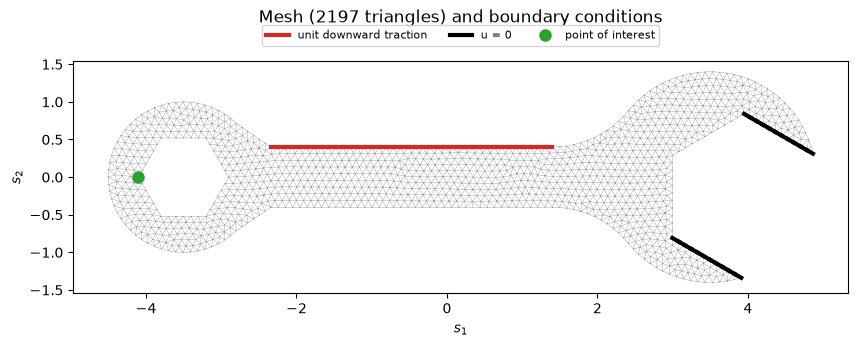

In [3]:
tri = mtri.Triangulation(nodes[:, 0], nodes[:, 1], tris)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.triplot(tri, lw=0.3, color='0.6')
for kind, color, label in [(1, 'tab:red', 'unit downward traction'), (2, 'k', 'u = 0')]:
    s = bnd[bnd[:, 2] == kind]
    for i, (a, b, _) in enumerate(s):
        ax.plot(nodes[[a, b], 0], nodes[[a, b], 1], color=color, lw=3, label=label if i == 0 else None)
ax.plot(-4.1, 0, 'o', color='tab:green', ms=8, label='point of interest')
ax.set_aspect('equal'); ax.set_xlabel('$s_1$'); ax.set_ylabel('$s_2$')
ax.legend(loc='upper center', ncol=3, fontsize=8, bbox_to_anchor=(0.5, 1.18))
ax.set_title('Mesh (2197 triangles) and boundary conditions', pad=28)
plt.close(fig)
fig

### Model check

The model is cheap, so the notebook re-runs it at five of the shipped samples and compares with the files. For a uniform change of all moduli, $E\to e^{c}E$, the displacement scales as $e^{-c}$, so the physical gradient satisfies $\sum_k \partial f/\partial X_k = -f$ exactly; the check prints how well the computed adjoint gradients satisfy it.

In [4]:
model = wm.Wrench()
t0 = time.perf_counter()
d_f, d_g, d_id = [], [], []
for i in range(5):
    fi, gx = model.f_and_grad(model.field(xi[i]))
    d_f.append(abs(fi - f[i]) / abs(f[i]))
    d_g.append(np.linalg.norm(Phi.T @ gx - G[i]) / np.linalg.norm(G[i]))
    d_id.append(abs(gx.sum() + fi) / abs(fi))
dt = (time.perf_counter() - t0) / 5
print(f'max relative difference from the files: f {max(d_f):.1e}, gradient {max(d_g):.1e}')
print(f'scaling identity |sum_k df/dX_k + f| / |f|: max {max(d_id):.1e}')
print(f'{dt * 1e3:.0f} ms per solve with adjoint gradient')

max relative difference from the files: f 2.6e-11, gradient 5.0e-11
scaling identity |sum_k df/dX_k + f| / |f|: max 4.0e-11
13 ms per solve with adjoint gradient


The re-run agrees with the files to the accuracy of the sparse direct solves (relative differences of order $10^{-11}$; the files were written on another platform, and differences at this level change with it), and the scaling identity holds to a relative error of the same order. The time per solve with its adjoint gradient is printed above (it depends on the machine and its load).

## Estimate the active subspace

The gradients are exact (adjoint), so we use the gradient estimator `'as'`. The inputs $\xi$ are already independent standard normals, the paper's standardized coordinates (p. 13), so the input space is `ac.Gaussian.reference(318)` and no further scaling is applied: every direction of the log-modulus field is measured in units of its own prior standard deviation through $\Phi$ (whitening, as in the paper). We keep $n = 3$, justified below, and draw 200 bootstrap replicates.

In [5]:
space = ac.Gaussian.reference(m)
sub = ac.active_subspace(space=space, X=xi, f=f, grads=G, estimator='as', n=3,
                         nboot=200, bootstrap_vectors=3, rng=SEED)
lam = sub.eigenvalues
lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, :8], [2.5, 97.5], axis=0)
for k in range(8):
    print(f'lambda_{k + 1} = {lam[k]:.4g}   (95% bootstrap interval {lo[k]:.4g} - {hi[k]:.4g})')
print('ratios lambda_k / lambda_(k+1), k = 1..7:', np.round(lam[:7] / lam[1:8], 2))
share = np.array([lam[k:].sum() / lam.sum() for k in range(1, 7)])
print('share of sum(lambda) left out by n = 1..6:', np.round(share, 4))

lambda_1 = 4.795e+06   (95% bootstrap interval 4.052e+06 - 5.661e+06)
lambda_2 = 3.67e+05   (95% bootstrap interval 2.982e+05 - 4.587e+05)
lambda_3 = 1.199e+05   (95% bootstrap interval 9.635e+04 - 1.47e+05)
lambda_4 = 1.94e+04   (95% bootstrap interval 1.633e+04 - 2.268e+04)
lambda_5 = 9717   (95% bootstrap interval 8008 - 1.141e+04)
lambda_6 = 6062   (95% bootstrap interval 5078 - 6737)
lambda_7 = 2897   (95% bootstrap interval 2394 - 3344)
lambda_8 = 2086   (95% bootstrap interval 1554 - 2388)
ratios lambda_k / lambda_(k+1), k = 1..7: [13.06  3.06  6.18  2.    1.6   2.09  1.39]
share of sum(lambda) left out by n = 1..6: [0.0995 0.0306 0.008  0.0044 0.0026 0.0014]


The eigenvalues fall by more than three orders of magnitude over the first eight indices. The largest ratio is $\lambda_1/\lambda_2 = 13.06$, the next largest $\lambda_3/\lambda_4 = 6.18$; the others among the first seven are between 1.39 and 3.06. One, two and three active variables leave out 0.0995, 0.0306 and 0.008 of the sum of the eigenvalues. The bootstrap intervals are wide in relative terms (for $\lambda_1$, 4.052×10⁶ to 5.661×10⁶) because the gradients are heavy-tailed, but the intervals of $\lambda_3$ and $\lambda_4$ (9.635×10⁴ to 1.47×10⁵ against 1.633×10⁴ to 2.268×10⁴) are far apart.

log10(reference) - log10(paper), k = 1..50: mean +0.001, range [-0.065, +0.031]
log10(this run) - log10(paper), k = 1..50: mean -0.082, range [-0.188, +0.029]
k = 1..5, paper: [4720600.  343600.  116900.   21900.   10200.]
k = 1..5, reference: [4524000.  356900.  112500.   22400.   10500.]
largest differences: -0.065 at k = 13, +0.031 at k = 44; |difference| > 0.02 at 10 of 50 indices
k = 1..5, reference / paper - 1 (%): [-4.2  3.9 -3.8  2.4  2.3]
k = 1..5, 95% bootstrap half-width / lambda_k at M = 1000 (%): [16.8 21.9 21.1 16.4 17.5] ; times 1/sqrt(10): [5.3 6.9 6.7 5.2 5.5]
expected sd of a log10 difference between two independent 10^4-sample estimates, k = 1..50: median 0.016, range 0.013 to 0.028
difference / expected sd: -2.3 at k = 13, +2.1 at k = 44; mean +0.12, sd 1.03; beyond 2 sd at 3 of 50 indices (largest 2.6, k = 38)
indices with |difference| > 0.02: expected 11.9 from Monte Carlo error alone, observed 10


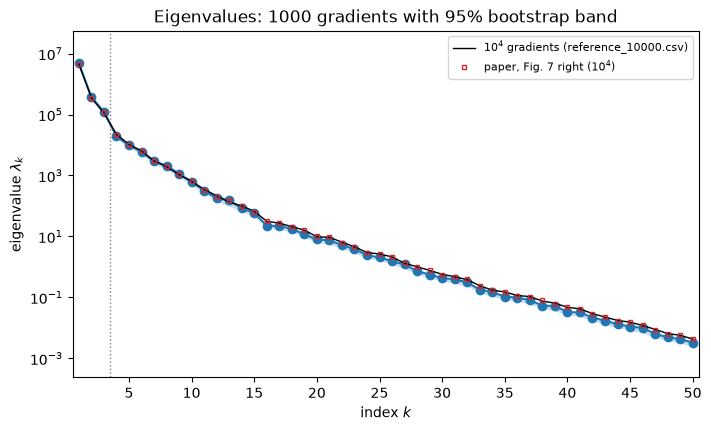

In [6]:
paper_fig7 = np.array([  # log10 eigenvalues of the 10^4-sample reference, Fig. 7 right (p. 15), read from the figure's vector paths
    6.674, 5.536, 5.068, 4.341, 4.010, 3.806, 3.478, 3.308, 3.041, 2.832, 2.517, 2.310, 2.194, 1.985, 1.802,
    1.495, 1.441, 1.317, 1.203, 1.024, 0.966, 0.784, 0.642, 0.462, 0.412, 0.319, 0.122, -0.012, -0.113, -0.251,
    -0.323, -0.408, -0.619, -0.768, -0.829, -0.957, -0.981, -1.085, -1.203, -1.325, -1.395, -1.539, -1.636,
    -1.787, -1.824, -1.907, -2.079, -2.192, -2.228, -2.354])
k = np.arange(1, 51)
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=50, figsize=(7, 4.2))
ax.plot(k, ref[:50, 0], 'k-', lw=1, label='$10^4$ gradients (reference_10000.csv)')
ax.plot(k, 10 ** paper_fig7, 's', color='tab:red', ms=3.5, mfc='none', label='paper, Fig. 7 right ($10^4$)')
ax.legend(fontsize=8)
ax.set_title('Eigenvalues: 1000 gradients with 95% bootstrap band')
d_paper = np.log10(ref[:50, 0]) - paper_fig7
d_ours = np.log10(lam[:50]) - paper_fig7
print(f'log10(reference) - log10(paper), k = 1..50: mean {d_paper.mean():+.3f}, range [{d_paper.min():+.3f}, {d_paper.max():+.3f}]')
print(f'log10(this run) - log10(paper), k = 1..50: mean {d_ours.mean():+.3f}, range [{d_ours.min():+.3f}, {d_ours.max():+.3f}]')
print('k = 1..5, paper:', np.round(10 ** paper_fig7[:5], -2))
print('k = 1..5, reference:', np.round(ref[:5, 0], -2))
print(f'largest differences: {d_paper.min():+.3f} at k = {d_paper.argmin() + 1}, {d_paper.max():+.3f} at k = {d_paper.argmax() + 1}; '
      f'|difference| > 0.02 at {np.sum(np.abs(d_paper) > 0.02)} of 50 indices')
print('k = 1..5, reference / paper - 1 (%):', np.round(100 * (10 ** d_paper[:5] - 1), 1))
lo5, hi5 = np.percentile(sub.bootstrap_eigenvalues[:, :5], [2.5, 97.5], axis=0)
hw = 100 * (hi5 - lo5) / 2 / lam[:5]
print('k = 1..5, 95% bootstrap half-width / lambda_k at M = 1000 (%):', np.round(hw, 1),
      '; times 1/sqrt(10):', np.round(hw / np.sqrt(10), 1))
# standard deviation of log10(lambda_k) over the bootstrap at M = 1000, scaled to the difference of two
# independent 10^4-sample estimates (the paper's and reference_10000.csv): times sqrt(2) / sqrt(10)
sd_diff = np.log10(np.abs(sub.bootstrap_eigenvalues[:, :50])).std(axis=0, ddof=1) * np.sqrt(2 / 10)
z = d_paper / sd_diff
n_exp = sum(math.erfc(0.02 / (s * math.sqrt(2))) for s in sd_diff)
print(f'expected sd of a log10 difference between two independent 10^4-sample estimates, k = 1..50: '
      f'median {np.median(sd_diff):.3f}, range {sd_diff.min():.3f} to {sd_diff.max():.3f}')
print(f'difference / expected sd: {z[12]:+.1f} at k = 13, {z[43]:+.1f} at k = 44; mean {z.mean():+.2f}, sd {z.std(ddof=1):.2f}; '
      f'beyond 2 sd at {np.sum(np.abs(z) > 2)} of 50 indices (largest {np.abs(z).max():.1f}, k = {np.abs(z).argmax() + 1})')
print(f'indices with |difference| > 0.02: expected {n_exp:.1f} from Monte Carlo error alone, observed {np.sum(np.abs(d_paper) > 0.02)}')
plt.close(fig)
fig

The $10^4$-gradient estimate (black line) lies close to the paper's reference eigenvalues (red squares, Fig. 7 right, p. 15) over all 50 indices: $\log_{10}$ differences from −0.065 ($k = 13$) to +0.031 ($k = 44$), mean +0.001. Ten of the 50 differences exceed 0.02 in $\log_{10}$, far more than the precision with which the figure was read (about 0.001), so the curves are not identical; they are as close as two independent Monte Carlo estimates can be expected to be. For $k = 1,\dots,5$ the paper's values are about 4.72×10⁶, 3.44×10⁵, 1.17×10⁵, 2.19×10⁴, 1.02×10⁴ and the reference's 4.52×10⁶, 3.57×10⁵, 1.13×10⁵, 2.24×10⁴, 1.05×10⁴, that is −4.2, +3.9, −3.8, +2.4 and +2.3 % off. Differences of this size are expected from two sources. Monte Carlo error: at $M = 1000$ the 95% bootstrap half-widths of $\lambda_1,\dots,\lambda_5$ are 16.8 to 21.9 % of the estimates, roughly 5.2 to 6.9 % after scaling by $1/\sqrt{10}$ for $10^4$ samples, so two independent $10^4$-sample estimates (the paper's and this one) can differ by several percent. Over the whole spectrum, the bootstrap at $M = 1000$, scaled by $\sqrt{2}/\sqrt{10}$ for the difference of two independent $10^4$-sample estimates, gives an expected standard deviation of the $\log_{10}$ difference of 0.016 (median over $k = 1,\dots,50$; range 0.013 to 0.028). Against it the difference at $k = 13$ is −2.3 standard deviations and the one at $k = 44$ is +2.1; 3 of the 50 lie beyond 2 standard deviations (largest 2.6, at $k = 38$), the standardized differences have mean +0.12 and standard deviation 1.03, and 11.9 differences larger than 0.02 are expected from Monte Carlo error alone against the 10 observed. Monte Carlo error alone thus accounts for the differences over the whole spectrum, including $k = 13$; if anything this scaling understates the scatter of two $10^4$-sample estimates (DATA.md, "How these files relate to the paper"). Discretization: the two meshes are different, with the same number of elements, and refining this data set's mesh moves the leading eigenvalues by a few percent (DATA.md, Accuracy). The agreement is therefore that of two Monte Carlo estimates on two discretizations of one problem, not a reproduction of the authors' runs. The 1000-gradient estimate (blue) is lower for the small eigenvalues ($\log_{10}$ differences from −0.188 to +0.029, mean −0.082), the usual downward bias of the trailing eigenvalues of a sample average.

mean bootstrap distance, k = 1..6: [0.026 0.06  0.046 0.1   0.142 0.123]


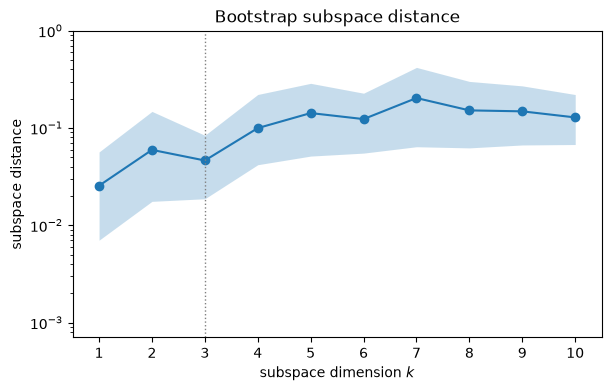

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=10, figsize=(6, 3.8))
ax.set_title('Bootstrap subspace distance')
err = sub.bootstrap_distances.mean(axis=0)[:6]
print('mean bootstrap distance, k = 1..6:', np.round(err, 3))
plt.close(fig)
fig

The mean bootstrap distances are 0.026, 0.06 and 0.046 for $k = 1, 2, 3$ and 0.1, 0.142, 0.123 for $k = 4, 5, 6$: the three-dimensional subspace is about as well determined as the one-dimensional one, and the error jumps after $k = 3$, where the eigenvalue ratio $\lambda_3/\lambda_4 = 6.18$ is.

### Eigenvectors as fields on the wrench

A component $w_{jk}$ multiplies the $j$-th basis field (column of $\Phi$), so the eigenvectors are best read as log-modulus fields $\Phi w_k$ on the mesh, as in the paper's Fig. 8 (p. 16). Signs: the paper's Fig. 8 shows mode 1 positive on the handle near $s_1\approx 1.3$ and mode 2 positive near the middle of the handle, $s_1\approx 0.3$; `ac.orient` makes the field positive at the triangle nearest those points (modes 1 and 2) and at the field's largest-magnitude entry (mode 3), and the reference eigenvectors from `reference_10000.csv` are compared with the same signs.

mode 1: field max +0.926 at s = [ 1.36 -0.02], min +0.000 at s = [-4.44 -0.24];  reference max +0.915 at s = [ 1.31 -0.04], min +0.000 at s = [-4.44 -0.24];  |w^T w_ref| = 0.9992
mode 2: field max +0.777 at s = [0.2  0.03], min -0.556 at s = [2.04 0.04];  reference max +0.752 at s = [0.2  0.03], min -0.589 at s = [ 2.09 -0.05];  |w^T w_ref| = 0.9981
mode 3: field max +0.559 at s = [-0.41  0.03], min -0.369 at s = [1.12 0.11];  reference max +0.609 at s = [-0.46 -0.05], min -0.378 at s = [ 1.12 -0.02];  |w^T w_ref| = 0.9962
mode 1 max: paper about +0.92; reference +0.915 (difference -0.005); 1000 gradients +0.926 (difference +0.006)
mode 2 max: paper about +0.77; reference +0.752 (difference -0.018); 1000 gradients +0.777 (difference +0.007)
mode 2 min: paper about -0.55; reference -0.589 (difference -0.039); 1000 gradients -0.556 (difference -0.006)


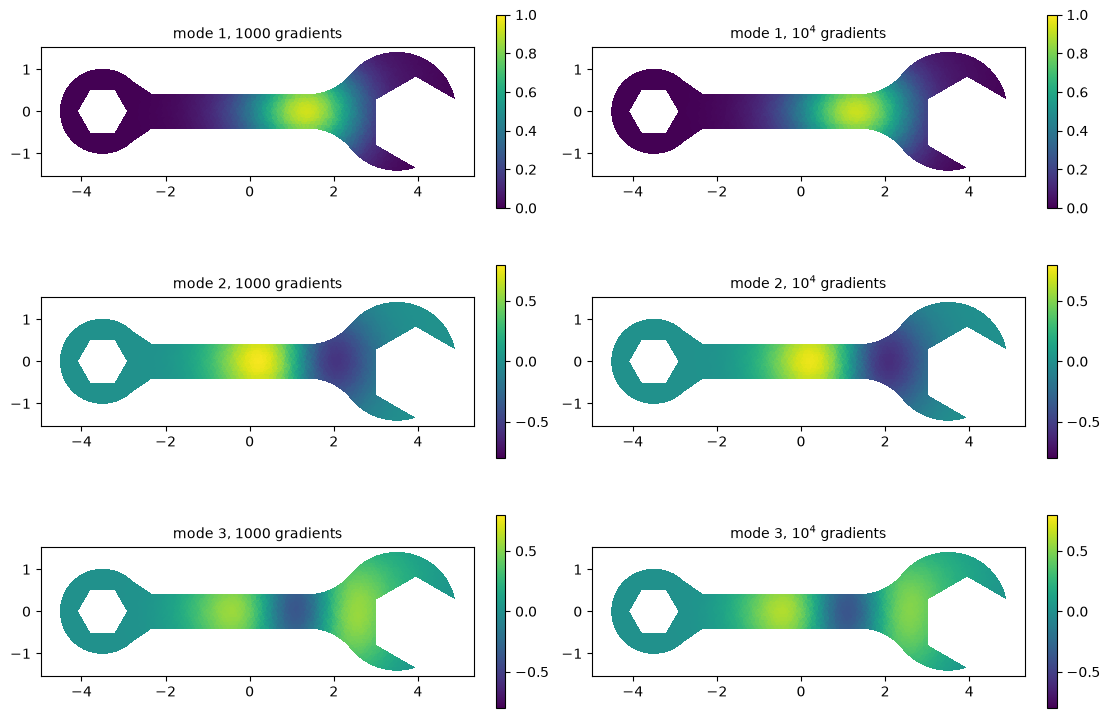

In [8]:
def nearest(point):
    return int(np.argmin(((cen - np.asarray(point)) ** 2).sum(1)))

W0 = sub.W[:, :3]
anchor = [nearest((1.3, 0.0)), nearest((0.3, 0.0)), int(np.argmax(np.abs(Phi @ W0[:, 2])))]
sub = ac.orient(sub, by='reference', reference=Phi[anchor].T, columns=3)
Wref = ref[:, 1:4] * np.sign(Phi[anchor] @ ref[:, 1:4]).diagonal()
fields = Phi @ sub.W[:, :3]
fields_ref = Phi @ Wref
for j in range(3):
    a = sub.W[:, j] @ Wref[:, j]
    print(f'mode {j + 1}: field max {fields[:, j].max():+.3f} at s = {np.round(cen[fields[:, j].argmax()], 2)}, '
          f'min {fields[:, j].min():+.3f} at s = {np.round(cen[fields[:, j].argmin()], 2)};  '
          f'reference max {fields_ref[:, j].max():+.3f} at s = {np.round(cen[fields_ref[:, j].argmax()], 2)}, '
          f'min {fields_ref[:, j].min():+.3f} at s = {np.round(cen[fields_ref[:, j].argmin()], 2)};  |w^T w_ref| = {abs(a):.4f}')
# Fig. 8 (p. 16), reference panels: extrema read from the colours (each pixel matched to the nearest colour of its
# colour bar, fixed limits [0, 1] for mode 1 and [-0.8, 0.8] for mode 2; precision about 0.02)
paper_fig8 = {'mode 1 max': (0, 'max', 0.92), 'mode 2 max': (1, 'max', 0.77), 'mode 2 min': (1, 'min', -0.55)}
for name, (j, kind, v) in paper_fig8.items():
    ext = (np.max if kind == 'max' else np.min)
    print(f'{name}: paper about {v:+.2f}; reference {ext(fields_ref[:, j]):+.3f} (difference {ext(fields_ref[:, j]) - v:+.3f}); '
          f'1000 gradients {ext(fields[:, j]):+.3f} (difference {ext(fields[:, j]) - v:+.3f})')
clims = [(0, 1), (-0.8, 0.8), (-0.8, 0.8)]   # modes 1 and 2 as in Fig. 8; mode 3 (not in the paper) as mode 2
fig, axs = plt.subplots(3, 2, figsize=(11, 7.5), constrained_layout=True)
for j in range(3):
    for col, (F, title) in enumerate([(fields[:, j], f'mode {j + 1}, 1000 gradients'),
                                      (fields_ref[:, j], f'mode {j + 1}, $10^4$ gradients')]):
        ax = axs[j, col]
        tp = ax.tripcolor(tri, facecolors=F, cmap='viridis', shading='flat', vmin=clims[j][0], vmax=clims[j][1])
        fig.colorbar(tp, ax=ax, shrink=0.8)
        ax.set_aspect('equal'); ax.set_xticks([-4, -2, 0, 2, 4]); ax.set_yticks([-1, 0, 1])
        ax.set_title(title, fontsize=10)
plt.close(fig)
fig

Mode 1 is a positive bump on the handle with its maximum 0.926 at $s = (1.36, -0.02)$, where the handle widens into the jaw, and it rounds to +0.000 on the ring: stiffening the root of the handle, where the bending moment of this cantilever is largest and the section narrowest, reduces the deflection of the ring. Mode 2 is positive in the middle of the handle (maximum 0.777 at $s_1 = 0.2$) and negative in the neck of the head (minimum −0.556 at $s_1 = 2.04$); mode 3 has three lobes along the handle and the head. The 1000- and $10^4$-gradient eigenvectors agree, with $|w_k^\top w_{k,\mathrm{ref}}| = $ 0.9992, 0.9981 and 0.9962. The paper's Fig. 8 (p. 16) shows the same two leading modes: mode 1 largest on the handle near $s_1\approx 1.3$, and mode 2 positive near $s_1\approx 0.3$ and negative near $s_1\approx 2.2$ (positions read by eye). Its colour bars have fixed limits, 0 to 1 for mode 1 and −0.8 to 0.8 for mode 2: the colour at the top of the mode-1 bar and those at both ends of the mode-2 bar do not occur in the fields. The figure above uses the same limits. Read from the colours, the paper's reference fields reach about 0.92 (mode 1) and about +0.77 and −0.55 (mode 2). The reference fields here reach 0.915, +0.752 and −0.589 (differences −0.005, −0.018 and −0.039) and the 1000-gradient fields 0.926, +0.777 and −0.556 (differences +0.006, +0.007 and −0.006), all within about the precision of reading values from colours. Shapes, positions of the extrema and amplitudes agree; the amplitudes are those of $\Phi w$ with a unit-norm eigenvector $w$, the quantity the authors' code plots ($\Sigma^{1/2}w$).

fraction of ||w_k||^2 outside the first 10 basis fields, k = 1..3: 1.4e-02, 5.1e-02, 1.2e-01
fraction of ||w_k||^2 outside the first 20 basis fields, k = 1..3: 4.5e-03, 5.6e-03, 1.5e-02
fraction of ||w_k||^2 outside the first 60 basis fields, k = 1..3: 2.6e-06, 9.9e-06, 4.8e-05
fraction of trace(C_hat) in basis fields beyond 100 and beyond 200: 3.1e-08, 3.4e-13


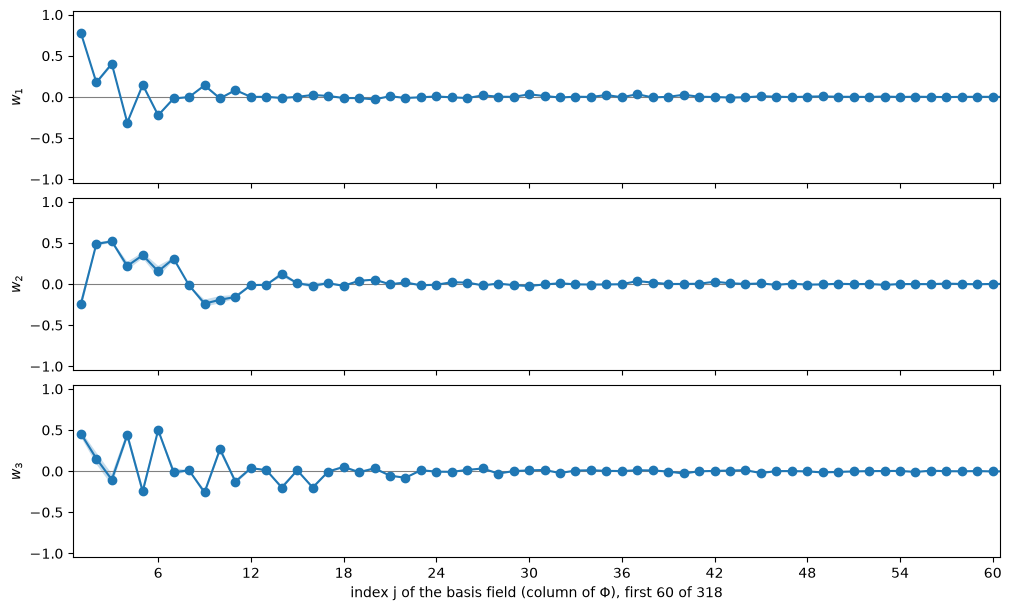

In [9]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2], interval='percentile', figsize=(10, 6))
for ax in axs:
    ax.set_xlim(0.5, 60.5)
axs[-1].set_xlabel('index j of the basis field (column of $\\Phi$), first 60 of 318')
for J in (10, 20, 60):
    out = 1 - (sub.W[:J, :3] ** 2).sum(axis=0)
    print(f'fraction of ||w_k||^2 outside the first {J} basis fields, k = 1..3:', ', '.join(f'{v:.1e}' for v in out))
tr = (G ** 2).sum()
print('fraction of trace(C_hat) in basis fields beyond 100 and beyond 200:', ', '.join(f'{(G[:, J:] ** 2).sum() / tr:.1e}' for J in (100, 200)))
plt.close(fig)
fig

In the basis $\Phi$, whose columns are ordered by decreasing eigenvalue of $\Sigma$ and so roughly by decreasing spatial scale, the three eigenvectors use only the smooth leading fields: the fraction of $\lVert w_k\rVert^2$ outside the first 20 basis fields is 4.5e-03, 5.6e-03 and 1.5e-02 for $k = 1, 2, 3$, and outside the first 60 it is 2.6e-06, 9.9e-06 and 4.8e-05. The bootstrap bands (95% percentile) are narrow on this scale. The basis fields beyond the 100th carry a fraction 3.1e-08 of the trace of $\hat C$, and those beyond the 200th 3.4e-13, so where exactly the basis of $\Sigma$ is cut off ($r = 318$, at the rounding level of $\Sigma$) does not matter for the active subspace.

correlation of f with y_1: 0.839; of log(-f) with y_1: -0.956


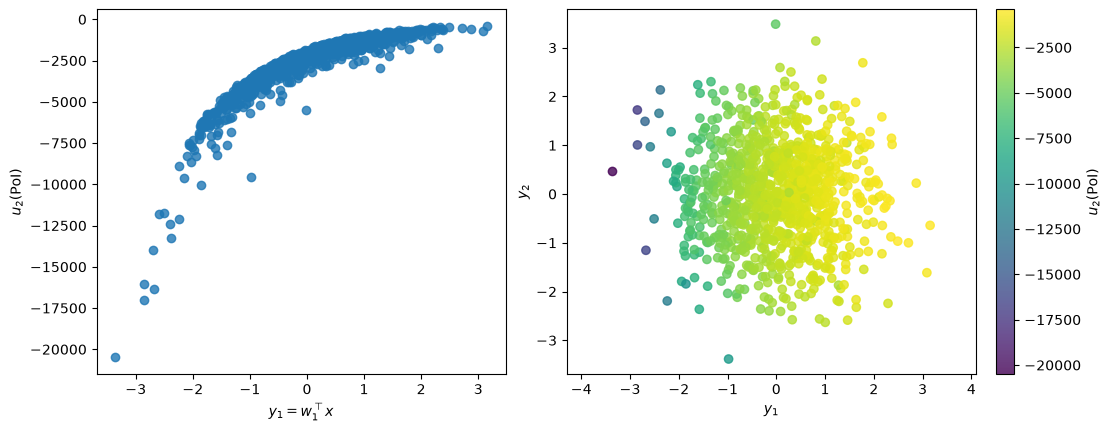

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, n=1), X=xi, f=f, ax=axs[0], qoi_label='$u_2(\\mathrm{PoI})$')
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, n=2), X=xi, f=f, ax=axs[1], qoi_label='$u_2(\\mathrm{PoI})$')
Y = xi @ sub.W[:, :3]
print(f'correlation of f with y_1: {np.corrcoef(f, Y[:, 0])[0, 1]:.3f}; of log(-f) with y_1: {np.corrcoef(np.log(-f), Y[:, 0])[0, 1]:.3f}')
plt.close(fig)
fig

Against $y_1$ the displacement follows one curved, monotone trend (correlation 0.839), steep for negative $y_1$ (a soft handle root) where the large deflections are; $\log(-f)$ is closer to linear in $y_1$ (correlation −0.956). In the $(y_1, y_2)$ plane the colour changes mainly along $y_1$.

### Surrogates on the active variables

Least-squares polynomials in $y = W_n^\top\xi$, $n = 1, 2, 3$, of degree 2 and 3, with leave-one-out $R^2$ (the leave-one-out residuals use the same 1000 samples that estimated $W$, so they are slightly optimistic).

In [11]:
loo = {}
for n in (1, 2, 3, 4):
    for deg in (2, 3):
        s = ac.fit_surrogate(X=xi, f=f, space=space, subspace=ac.with_dimension(sub, n=n), kind='poly', degree=deg)
        loo[n, deg] = s.loo_r_squared
        print(f'n = {n}, degree {deg}: LOO R^2 = {s.loo_r_squared:.4f}')

n = 1, degree 2: LOO R^2 = 0.8879
n = 1, degree 3: LOO R^2 = 0.9320
n = 2, degree 2: LOO R^2 = 0.9176
n = 2, degree 3: LOO R^2 = 0.9698
n = 3, degree 2: LOO R^2 = 0.9272
n = 3, degree 3: LOO R^2 = 0.9860
n = 4, degree 2: LOO R^2 = 0.9268
n = 4, degree 3: LOO R^2 = 0.9863


### Choice of dimension: $n = 3$

- **Eigenvalue gaps.** The largest ratio is $\lambda_1/\lambda_2 = 13.06$ and the second $\lambda_3/\lambda_4 = 6.18$; $\lambda_2/\lambda_3 = 3.06$, $\lambda_4/\lambda_5 = 2.0$ and $\lambda_5/\lambda_6 = 1.6$ are comparable to the ratios further down, so there is no clear gap after $k = 2$ or $k = 4, 5$.
- **Subspace error.** The bootstrap distance is 0.046 at $k = 3$, below its value at $k = 2$ (0.06) and less than half of that at $k = 4$ (0.1).
- **Left-out share.** $n = 3$ leaves out 0.008 of the sum of the eigenvalues; $n = 1$ leaves out 0.0995.
- **Surrogates.** The cubic's LOO $R^2$ rises from 0.932 ($n = 1$) to 0.9698 ($n = 2$) and 0.986 ($n = 3$), then stops (0.9863 at $n = 4$).

A one-dimensional summary is a fair first approximation (LOO $R^2$ 0.932 with a cubic); three active variables capture the displacement to LOO $R^2$ 0.986. The paper reads "a few modes (≈ 5)" from the same spectral decay (p. 14); with $\lambda_4/\lambda_5 = 2.0$ and $\lambda_5/\lambda_6 = 1.6$, this data set finds no gap that would single out five.

## Comparison with the paper

In [12]:
print(f'number of elements: paper 2197 (p. 13), here {tris.shape[0]}')
for kk in (1, 2, 3, 4, 5, 10, 20, 50):
    print(f'lambda_{kk}: paper 10^{paper_fig7[kk - 1]:.3f} = {10 ** paper_fig7[kk - 1]:.4g}; '
          f'reference (10^4) {ref[kk - 1, 0]:.4g}; this run (1000) {lam[kk - 1]:.4g}')

number of elements: paper 2197 (p. 13), here 2197
lambda_1: paper 10^6.674 = 4.721e+06; reference (10^4) 4.524e+06; this run (1000) 4.795e+06
lambda_2: paper 10^5.536 = 3.436e+05; reference (10^4) 3.569e+05; this run (1000) 3.67e+05
lambda_3: paper 10^5.068 = 1.169e+05; reference (10^4) 1.125e+05; this run (1000) 1.199e+05
lambda_4: paper 10^4.341 = 2.193e+04; reference (10^4) 2.245e+04; this run (1000) 1.94e+04
lambda_5: paper 10^4.010 = 1.023e+04; reference (10^4) 1.047e+04; this run (1000) 9717
lambda_10: paper 10^2.832 = 679.2; reference (10^4) 633.6; this run (1000) 624.9
lambda_20: paper 10^1.024 = 10.57; reference (10^4) 9.731; this run (1000) 8.03
lambda_50: paper 10^-2.354 = 0.004426; reference (10^4) 0.004297; this run (1000) 0.003232


| quantity | paper (page) | this notebook |
|---|---|---|
| number of elements $d$ | 2197 (p. 13) | 2197 (a different mesh, `wrench_mesh.py`) |
| low-fidelity mesh | 423 elements (p. 13) | not built |
| samples for the reference matrix | $10^4$ (p. 14) | $10^4$ (`reference_10000.csv`); 1000 for the analysis above |
| $\lambda_1,\dots,\lambda_5$ of the reference | 4.721×10⁶, 3.436×10⁵, 1.169×10⁵, 2.193×10⁴, 1.023×10⁴ (Fig. 7 right, p. 15; read from the figure) | $10^4$: 4.524×10⁶, 3.569×10⁵, 1.125×10⁵, 2.245×10⁴, 1.047×10⁴; 1000: 4.795×10⁶, 3.67×10⁵, 1.199×10⁵, 1.94×10⁴, 9717 |
| $\lambda_{10}, \lambda_{20}, \lambda_{50}$ | 679.2, 10.57, 0.004426 (Fig. 7 right) | $10^4$: 633.6, 9.731, 0.004297; 1000: 624.9, 8.03, 0.003232 |
| $\log_{10}$ difference, $k = 1,\dots,50$ | — | $10^4$: −0.065 to +0.031 (mean +0.001); 1000: −0.188 to +0.029 (mean −0.082) |
| number of important modes | "≈ 5" (p. 14) | $n = 3$ chosen (gaps 13.06 after $k = 1$, 6.18 after $k = 3$) |
| mode 1 | largest on the handle near $s_1\approx1.3$, maximum about 0.92 (Fig. 8, p. 16; colour bar fixed at 0 to 1) | maximum 0.926 at $s = (1.36, -0.02)$; reference 0.915 at $(1.31, -0.04)$ |
| mode 2 | positive near $s_1\approx0.3$ (about +0.77), negative near $s_1\approx2.2$ (about −0.55) (Fig. 8; colour bar fixed at −0.8 to 0.8) | +0.777 at $s_1 = 0.2$, −0.556 at $s_1 = 2.04$; reference +0.752 at $s_1 = 0.2$, −0.589 at $s_1 = 2.09$ |
| mode extrema minus the paper's (mode 1 max; mode 2 max, min) | — | reference −0.005; −0.018, −0.039; 1000 gradients +0.006; +0.007, −0.006 |
| relative error of SF and MF estimators | 0.4 reached at $\gamma = 7$ (SF) and $\gamma = 4$ (MF) (Fig. 7 left, p. 14) | not reported (no low-fidelity model) |
| cost of $\nabla g$ relative to $\nabla f$ | about 7 times cheaper (p. 13) | not reported |
| cost of one solve with adjoint gradient | not reported | printed in the model check above |

The paper's eigenvalues are read from the vector drawing of Fig. 7 in the arXiv v2 PDF (marker centres, to about 0.001 in $\log_{10}$); the published SISC figures were not checked. The paper's statements about the modes are qualitative; the positions above are read from its Fig. 8 by eye, and the extrema from the colours of its reference panels against their fixed colour bars (to about 0.02). The reference eigenvalues differ from the paper's by up to 0.065 in $\log_{10}$ ($k = 13$), well beyond the reading precision but −2.3 times the expected Monte Carlo standard deviation of the difference; over all 50 indices the differences are of the size expected from Monte Carlo error alone, before the different mesh is counted. The two leading mode fields agree with Fig. 8 in shape, position and amplitude.

## References

- R. R. Lam, O. Zahm, Y. M. Marzouk, K. E. Willcox. Multifidelity dimension reduction via active subspaces. *SIAM Journal on Scientific Computing* 42(2):A929–A956, 2020. [doi:10.1137/18M1214123](https://doi.org/10.1137/18M1214123)
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- O. Zahm. wrenchmark (MATLAB, PDE Toolbox), https://gitlab.inria.fr/ozahm/wrenchmark, the code cited in the paper (footnote 2, p. 13); its geometry and boundary set-up were rebuilt here, its code was not copied.

## Acknowledgments

The paper's work was funded in part by the AFOSR MURI on multi-information sources of multi-physics systems, Award Number FA9550-15-1-0038 (p. 1).